# Chapter 7 — How to Picture Neural Networks: In Your Head and on Paper
### Reproduction & Theoretical Deep-Dive — *grokking Deep Learning* (Manning)

By Chapter 6 we can build and train a network with a hidden layer, but a network is just **thousands of numbers**.
This chapter is about *mental models*: how to compress those numbers into pictures and short notation so you can
reason about a network without staring at arrays. Three ideas organise it:

1. a network is a **correlation summarizer** — its weights record which inputs go together with which outputs;
2. a compact **notation** (letters for layers, shapes for matrices) lets you draw a whole network in one line;
3. because it only knows correlation, a network can learn the **wrong** pattern — so you must be able to look inside.

> **Note on the examples.** The book illustrates these ideas with its own small examples. Here I use the
> **8×8 handwritten-digit images that ship with scikit-learn** (1,797 images) so that the weights of a network can be drawn
> as small pictures. The demos are my own; the ideas and the order follow the chapter.

**Roadmap**
1. Notation and the "one-line picture" of a network
2. Weights as a correlation summary (one output)
3. One picture per output (ten digits)
4. What do hidden units look like?
5. Danger: a network only knows correlation

train: (1200, 64)  test: (597, 64)


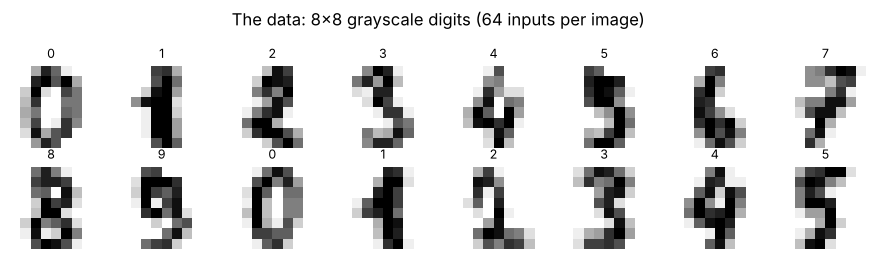

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

os.makedirs('outputs', exist_ok=True)
np.set_printoptions(precision=3, suppress=True)

digits = load_digits()
X_all = digits.data / 16.0                      # pixel intensities scaled to [0, 1], 64 pixels per image
y_all = digits.target

rng = np.random.default_rng(0)
order = rng.permutation(len(X_all))
tr, te = order[:1200], order[1200:]
Xtr, ytr, Xte, yte = X_all[tr], y_all[tr], X_all[te], y_all[te]
print('train:', Xtr.shape, ' test:', Xte.shape)

fig, axes = plt.subplots(2, 8, figsize=(9, 2.6))
for ax, img, label in zip(axes.ravel(), digits.images[:16], digits.target[:16]):
    ax.imshow(img, cmap='gray_r'); ax.set_title(str(label), fontsize=9); ax.axis('off')
plt.suptitle('The data: 8x8 grayscale digits (64 inputs per image)')
plt.tight_layout()
plt.savefig('outputs/digit_samples.png', dpi=110)
plt.show()

## 1. Notation and the one-line picture

When you read papers or other people's code you will see the same shorthand again and again. It is worth fixing it in your head:

| Symbol | Meaning | Shape (for a batch of $N$ examples) |
|---|---|---|
| $\mathbf l_0 = X$ | input layer (the data) | $(N,\ n_0)$ |
| $W_{01}$ | weights from layer 0 to layer 1 | $(n_0,\ n_1)$ |
| $\mathbf l_1=\operatorname{relu}(\mathbf l_0W_{01})$ | hidden layer | $(N,\ n_1)$ |
| $W_{12}$ | weights from layer 1 to layer 2 | $(n_1,\ n_2)$ |
| $\mathbf l_2=\mathbf l_1W_{12}$ | output layer (the prediction) | $(N,\ n_2)$ |
| $\boldsymbol\delta_k$ | error signal ("blame") at layer $k$ | same shape as $\mathbf l_k$ |

**Rule of thumb:** *the weight matrix between two layers has one row per unit on its left and one column per unit on its right.*
So a one-line picture is simply the list of layer sizes, e.g. **64 → 24 → 10**: it tells you the shape of every matrix
($64\times24$ and $24\times10$) and therefore how many weights the network has.

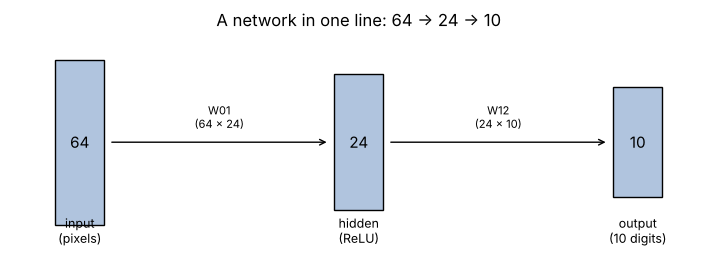

W01: ( 64 x  24)  ->   1536 weights
W12: ( 24 x  10)  ->    240 weights
total: 1776 weights

W01: ( 64 x 128)  ->   8192 weights
W12: (128 x 128)  ->  16384 weights
W23: (128 x  10)  ->   1280 weights
total: 25856 weights


In [2]:
def draw_layer_diagram(sizes, names, title, filename):
    fig, ax = plt.subplots(figsize=(9, 2.8))
    ax.set_xlim(0, 10); ax.set_ylim(0, 3); ax.axis('off')
    xs = np.linspace(1, 9, len(sizes))
    for x, s, nm in zip(xs, sizes, names):
        h = 0.5 + 1.8 * np.log10(s + 1) / np.log10(max(sizes) + 1)       # box height ~ log(size)
        ax.add_patch(plt.Rectangle((x - 0.35, 1.5 - h / 2), 0.7, h, fc='lightsteelblue', ec='k'))
        ax.text(x, 1.5, str(s), ha='center', va='center', fontsize=11)
        ax.text(x, 0.1, nm, ha='center', fontsize=9)
    for k in range(len(sizes) - 1):
        ax.annotate('', xy=(xs[k + 1] - 0.42, 1.5), xytext=(xs[k] + 0.42, 1.5), arrowprops=dict(arrowstyle='->'))
        ax.text((xs[k] + xs[k + 1]) / 2, 1.7, f'W{k}{k+1}\n({sizes[k]} x {sizes[k+1]})', ha='center', fontsize=8)
    ax.set_title(title)
    plt.savefig(filename, dpi=110, bbox_inches='tight')
    plt.show()

draw_layer_diagram([64, 24, 10], ['input\n(pixels)', 'hidden\n(ReLU)', 'output\n(10 digits)'],
                   'A network in one line: 64 -> 24 -> 10', 'outputs/network_one_line.png')

def describe_network(sizes):
    total = 0
    for k in range(len(sizes) - 1):
        n = sizes[k] * sizes[k + 1]
        total += n
        print(f"W{k}{k+1}: ({sizes[k]:3d} x {sizes[k+1]:3d})  ->  {n:5d} weights")
    print(f"total: {total} weights")

describe_network([64, 24, 10])
print()
describe_network([64, 128, 128, 10])

**Reading the output.** From the one-line picture alone we can predict that the first network has $64\cdot24+24\cdot10=1776$ weights and the
second, deeper one has $64\cdot128+128\cdot128+128\cdot10=25{,}856$. Counting weights this way is the quickest sanity check
when a network is slow, memory-hungry or prone to over-fitting.

## 2. Weights as a correlation summary

The book's central picture: **a layer of weights summarises the correlations between its inputs and the thing it must predict.**
Positive weight ↔ "when this input is high, the target tends to be high"; negative weight ↔ "when this input is high,
the target tends to be low"; weight near 0 ↔ "this input says nothing".

Let me test that claim directly. Task: output 1 if the image is a **3**, else 0. I will
1. compute the plain **correlation** between every pixel and the target, and
2. train a one-layer network (the Chapter 5 recipe: $W\leftarrow W-\alpha\,X^\top\boldsymbol\delta/N$) and look at its weights.

Since the images are $8\times8$, either set of 64 numbers can be shown as a small picture.

correlation between the learned weights and the raw pixel-target correlations: 0.535


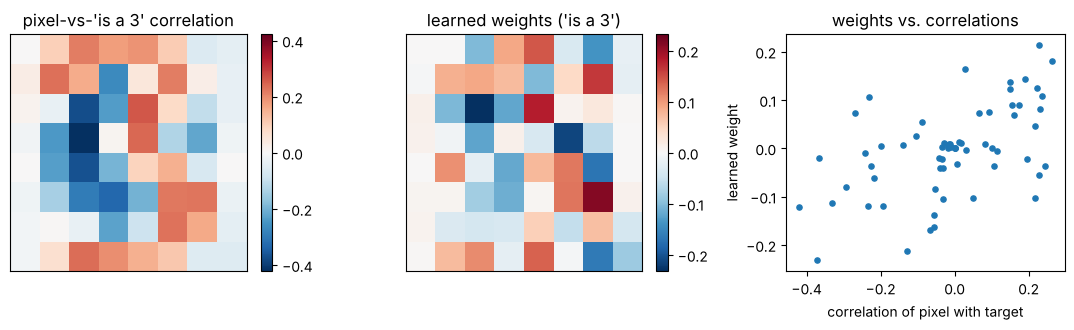

In [3]:
def corr_with_target(X, t):
    Xc, tc = X - X.mean(axis=0), t - t.mean()
    denom = np.sqrt((Xc ** 2).sum(axis=0) * (tc ** 2).sum())
    return np.divide(Xc.T @ tc, denom, out=np.zeros(X.shape[1]), where=denom > 0)

def train_linear(X, T, lr=0.1, epochs=3000):
    # one layer, no hidden units: batch gradient descent on the mean squared error
    N = len(X)
    W, b = np.zeros((X.shape[1], T.shape[1])), np.zeros(T.shape[1])
    for _ in range(epochs):
        D = X @ W + b - T
        W -= lr * X.T @ D / N
        b -= lr * D.mean(axis=0)
    return W, b

t_tr = (ytr == 3).astype(float)
corr_map = corr_with_target(Xtr, t_tr)
W3, b3 = train_linear(Xtr, t_tr.reshape(-1, 1))
w_map = W3[:, 0]

print("correlation between the learned weights and the raw pixel-target correlations:",
      round(np.corrcoef(w_map, corr_map)[0, 1], 3))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
vmax = np.abs(corr_map).max()
im0 = axes[0].imshow(corr_map.reshape(8, 8), cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[0].set_title("pixel-vs-'is a 3' correlation"); plt.colorbar(im0, ax=axes[0], fraction=0.046)
wmax = np.abs(w_map).max()
im1 = axes[1].imshow(w_map.reshape(8, 8), cmap='RdBu_r', vmin=-wmax, vmax=wmax)
axes[1].set_title("learned weights ('is a 3')"); plt.colorbar(im1, ax=axes[1], fraction=0.046)
axes[2].scatter(corr_map, w_map, s=14)
axes[2].set_xlabel('correlation of pixel with target'); axes[2].set_ylabel('learned weight')
axes[2].set_title('weights vs. correlations')
for a in axes[:2]:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout()
plt.savefig('outputs/weights_vs_correlation.png', dpi=110)
plt.show()

**Reading the output.** The two pictures are clearly related: red (positive) where a pixel being "ink" goes together with the digit being a 3, blue (negative)
where ink in that spot argues against it. The scatter plot on the right shows a clear positive trend, but a loose one (the correlation printed above is only about 0.5).

That looseness is the subtlety worth knowing: the weights are **not identical** to the raw correlations. A correlation looks at each pixel *in isolation*, while the
network sets all weights **jointly** — if two neighbouring pixels carry the same information, the weights split the credit between them and may even give
one of them a negative weight to correct the other. "Correlation summarizer" is a good first picture, but the full story is *joint* correlation.

## 3. One picture per output

With 10 output units, each output has its own column of $W$, so each digit gets its own $8\times8$ weight picture. This is the multi-output
case of Chapter 5. Each picture is the "template" that the corresponding output is correlating the image with.

one-layer network  train accuracy: 0.947   test accuracy: 0.938


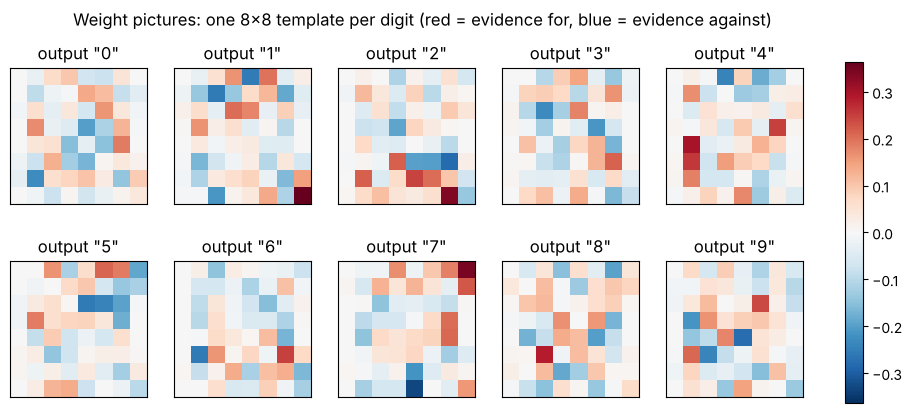

In [4]:
T_tr = np.eye(10)[ytr]                                   # one-hot targets, shape (1200, 10)
W10, b10 = train_linear(Xtr, T_tr, lr=0.1, epochs=3000)

pred_te = (Xte @ W10 + b10).argmax(axis=1)
pred_tr = (Xtr @ W10 + b10).argmax(axis=1)
print(f"one-layer network  train accuracy: {np.mean(pred_tr == ytr):.3f}   test accuracy: {np.mean(pred_te == yte):.3f}")

fig, axes = plt.subplots(2, 5, figsize=(11, 4.6))
wmax = np.abs(W10).max()
for d, ax in enumerate(axes.ravel()):
    im = ax.imshow(W10[:, d].reshape(8, 8), cmap='RdBu_r', vmin=-wmax, vmax=wmax)
    ax.set_title(f'output "{d}"'); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, fraction=0.02)
plt.suptitle('Weight pictures: one 8x8 template per digit (red = evidence for, blue = evidence against)')
plt.savefig('outputs/weight_templates_per_digit.png', dpi=110, bbox_inches='tight')
plt.show()

**Reading the output.** Even this tiny network (no hidden layer) classifies unseen digits well, and its weight pictures are readable: you can see strokes of the
digit in red and the places where ink would contradict it in blue. This is the practical payoff of the chapter's pictures: **when you understand
what a weight means, a table of 640 numbers becomes ten images you can inspect.**

## 4. What do hidden units look like?

A hidden unit is also just a column of weights — one for each input pixel — so it too can be drawn as an $8\times8$ picture (its "receptive field").
We now train the Chapter 6 network (ReLU hidden layer, backpropagation) on the digits and look at what its units have become.
Unlike the output templates, nobody told the hidden units what to detect: they discover **useful intermediate features** by themselves.

64 -> 24 -> 10 network  train accuracy: 0.961   test accuracy: 0.951


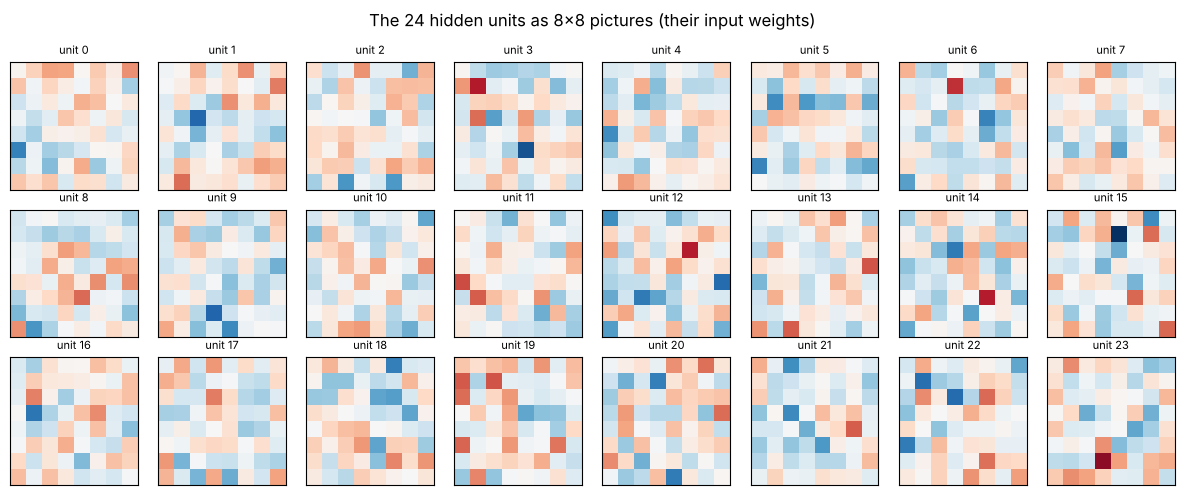

In [5]:
def train_mlp(X, T, hidden=24, lr=0.1, epochs=800, seed=0):
    rng = np.random.default_rng(seed)
    W01 = rng.normal(0, 0.2, (X.shape[1], hidden))
    W12 = rng.normal(0, 0.2, (hidden, T.shape[1]))
    N = len(X)
    for _ in range(epochs):
        z1 = X @ W01
        l1 = np.maximum(0, z1)
        d2 = l1 @ W12 - T                                # error at the output
        d1 = (d2 @ W12.T) * (z1 > 0)                     # blame sent backwards through W12 and the ReLU
        W12 -= lr * l1.T @ d2 / N
        W01 -= lr * X.T @ d1 / N
    return W01, W12

W01, W12 = train_mlp(Xtr, T_tr, hidden=24)
def mlp_predict(X): return (np.maximum(0, X @ W01) @ W12).argmax(axis=1)
print(f"64 -> 24 -> 10 network  train accuracy: {np.mean(mlp_predict(Xtr) == ytr):.3f}   test accuracy: {np.mean(mlp_predict(Xte) == yte):.3f}")

fig, axes = plt.subplots(3, 8, figsize=(12, 5))
wmax = np.abs(W01).max()
for u, ax in enumerate(axes.ravel()):
    ax.imshow(W01[:, u].reshape(8, 8), cmap='RdBu_r', vmin=-wmax, vmax=wmax)
    ax.set_title(f'unit {u}', fontsize=8); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('The 24 hidden units as 8x8 pictures (their input weights)')
plt.tight_layout()
plt.savefig('outputs/hidden_unit_pictures.png', dpi=110)
plt.show()

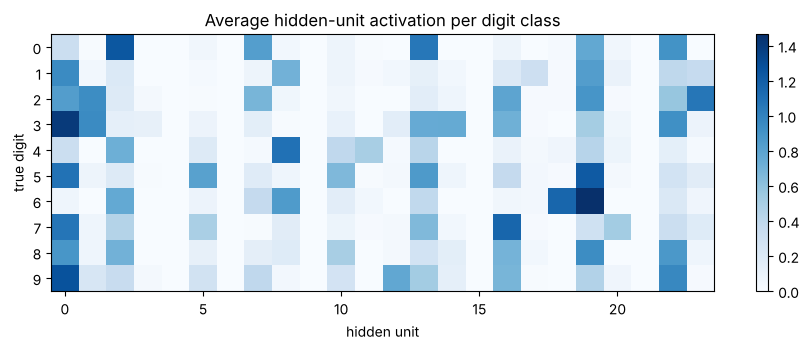

In [6]:
# Which hidden units "light up" for which kind of digit?  Average activation per digit class.
act = np.maximum(0, Xte @ W01)
mean_act = np.array([act[yte == d].mean(axis=0) for d in range(10)])      # shape (10 digits, 24 units)

fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(mean_act, cmap='Blues', aspect='auto')
ax.set_yticks(range(10)); ax.set_xlabel('hidden unit'); ax.set_ylabel('true digit')
ax.set_title('Average hidden-unit activation per digit class')
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig('outputs/hidden_activation_by_digit.png', dpi=110)
plt.show()

**Reading the output.** Hidden-unit pictures are noisier and less obviously "digit-shaped" than the output templates — they are *parts and combinations*, not whole digits.
The heat-map shows that each digit class has its own **fingerprint** of active units: a handful of units fire strongly for one digit and stay quiet for others.
That is the "intermediate representation" idea in action: the output layer no longer looks at raw pixels, it looks at this fingerprint.

## 5. A network only knows correlation — so it can learn the wrong thing

Because weights summarise correlation, a network will happily use **any** input that correlates with the target in the training set, whether or
not it is a real cause. To see this, I add a 65th input, a "sticker", that in the **training** data is *perfectly* correlated with the label
("is it a 3?"), but in the **test** data is just a coin flip (as if the sticker only existed because of how the training set was collected).

In [7]:
def balanced_accuracy(pred, t):
    # mean of the recall on the positive class and the recall on the negative class
    return 0.5 * (np.mean(pred[t == 1] > 0.5) + np.mean(pred[t == 0] <= 0.5))

t_te = (yte == 3).astype(float)
rng = np.random.default_rng(1)

sticker_tr = t_tr.reshape(-1, 1)                                         # copies the label during training
sticker_te = rng.integers(0, 2, size=(len(Xte), 1)).astype(float)        # unrelated to the label at test time

Xtr_s, Xte_s = np.hstack([Xtr, sticker_tr]), np.hstack([Xte, sticker_te])

W_plain, b_plain = train_linear(Xtr, t_tr.reshape(-1, 1))
W_stk, b_stk = train_linear(Xtr_s, t_tr.reshape(-1, 1))

rows = [('pixels only', balanced_accuracy((Xtr @ W_plain + b_plain)[:, 0], t_tr), balanced_accuracy((Xte @ W_plain + b_plain)[:, 0], t_te)),
        ('pixels + sticker', balanced_accuracy((Xtr_s @ W_stk + b_stk)[:, 0], t_tr), balanced_accuracy((Xte_s @ W_stk + b_stk)[:, 0], t_te))]
print("model              | train balanced acc | test balanced acc")
for name, a, b in rows:
    print(f"{name:18s} | {a:18.3f} | {b:17.3f}")

print()
print(f"weight on the sticker: {W_stk[-1, 0]:.3f}   largest |pixel weight|: {np.abs(W_stk[:-1, 0]).max():.3f}")

model              | train balanced acc | test balanced acc
pixels only        |              0.903 |             0.906
pixels + sticker   |              1.000 |             0.471

weight on the sticker: 0.998   largest |pixel weight|: 0.005


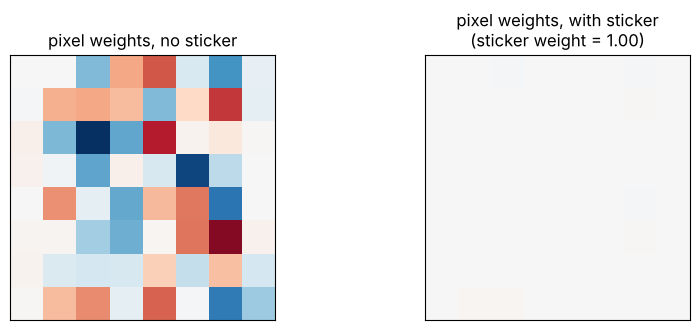

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
w1, w2 = W_plain[:, 0], W_stk[:-1, 0]
wmax = max(np.abs(w1).max(), np.abs(w2).max())
axes[0].imshow(w1.reshape(8, 8), cmap='RdBu_r', vmin=-wmax, vmax=wmax); axes[0].set_title('pixel weights, no sticker')
axes[1].imshow(w2.reshape(8, 8), cmap='RdBu_r', vmin=-wmax, vmax=wmax); axes[1].set_title(f'pixel weights, with sticker\n(sticker weight = {W_stk[-1, 0]:.2f})')
for a in axes:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout()
plt.savefig('outputs/sticker_weights.png', dpi=110)
plt.show()

**Reading the output.** With the sticker available, the training score rises from about 0.90 to a perfect 1.00, and almost all of the work is delegated to the sticker weight (about 1.0, versus at most 0.005 for any pixel): the digit pixels are barely needed.
On the test set, where the sticker no longer tracks the label, the score falls to about 0.47 — no better than a coin flip, and far worse than the honest pixels-only model's 0.90.
The *training* numbers looked fine — only looking at the weights (or testing on data collected differently) reveals the problem.
This is the strongest argument for the chapter's message: **learn to look inside the network, because it will exploit whatever correlation is easiest to find.**

## Summary

| Idea | Takeaway |
|---|---|
| Notation | $\mathbf l_0, W_{01}, \mathbf l_1, W_{12}, \mathbf l_2$ and deltas; matrix has one row per left unit, one column per right unit |
| One-line picture | layer sizes (64 → 24 → 10) give every matrix shape and the weight count |
| Weights = correlation summary | positive: goes with the target; negative: goes against; ~0: irrelevant — but *jointly*, not pixel by pixel |
| Pictures of weights | output templates are readable; hidden units are intermediate features |
| Danger | the network will use any correlation, including a spurious one — inspect, and test on differently collected data |